In [ ]:
#Major Project Enhanced
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error, ConfusionMatrixDisplay

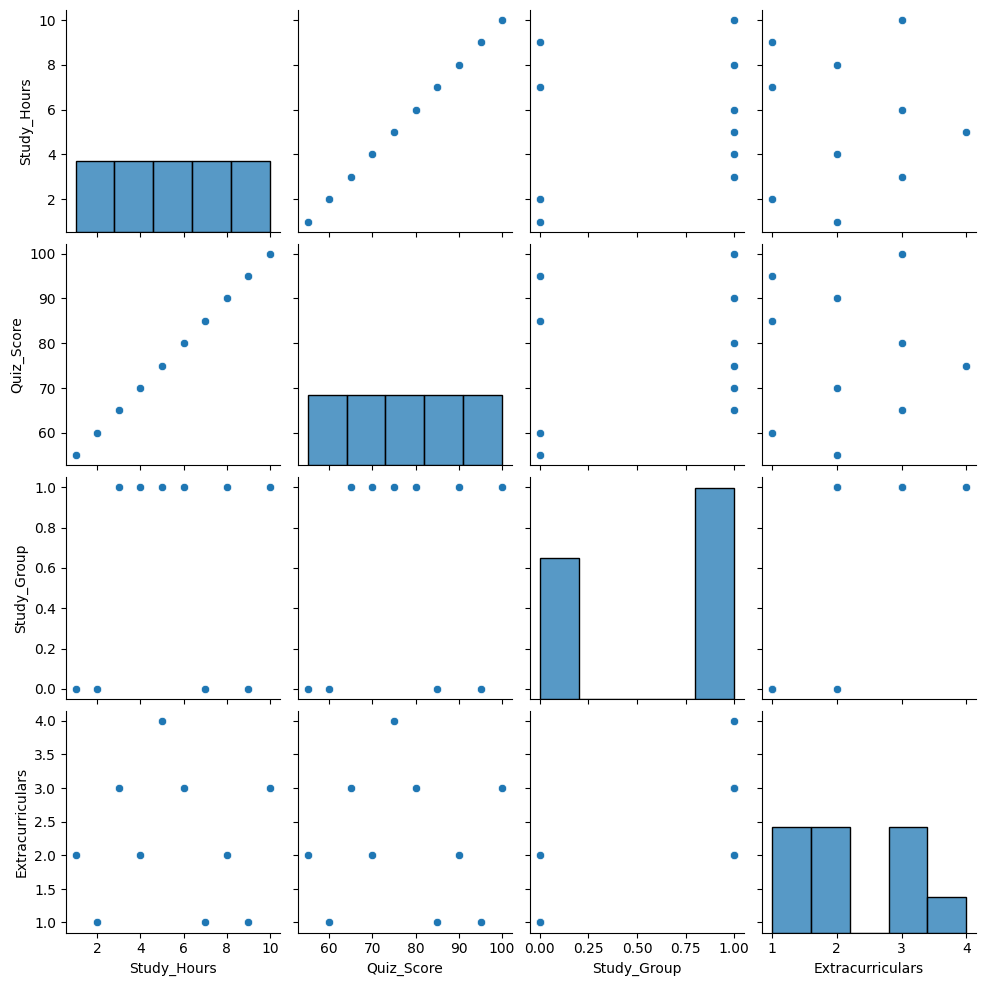

In [ ]:
data = pd.DataFrame({
  'Study_Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
  'Quiz_Score': [55, 60, 65, 70, 75, 80, 85, 90, 95, 100],
  'Study_Group':[0,  0,  1,  1, 1, 1, 0, 1, 0, 1],
  'Extracurriculars':[2, 1, 3, 2, 4, 3, 1, 2, 1, 3],
  'Pass/Fail': ['Fail', 'Fail', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass']
})

sns.pairplot(data)

In [ ]:
mean = data['Quiz_Score'].mean()
mode = 'No Mode'
median = data['Quiz_Score'].median()

print(f'Mean of Quiz Scores" {mean:.2f} \n Mode of Quiz Scores: {mode} \n Median of Quiz Scores: {median:.2f}')

Mean of Quiz Scores" 77.50 
 Mode of Quiz Scores: No Mode 
 Median of Quiz Scores: 77.50


In [ ]:
X = data.drop(columns=['Quiz_Score', 'Pass/Fail'])
y = data['Pass/Fail'].map({'Fail':0, 'Pass':1})
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_reg = data[['Study_Hours']]
y_reg = data['Quiz_Score']

X_train_reg, Y_train_reg, X_test_reg, Y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

In [ ]:
tree = DecisionTreeClassifier()
tree.fit(X_train, Y_train)

tree_pred = tree.predict(X_test)
class_report = classification_report(Y_test, tree_pred)
cm = confusion_matrix(Y_test, tree_pred)
print(f"Decision Tree's Classification Report: {class_report} \n Decision Tree's Confusion Matrix: ")
print(cm)

forest = RandomForestClassifier()
forest.fit(X_train, Y_train)

forest_pred = forest.predict(X_test)
accuracy = accuracy_score(Y_test, forest_pred)
print(f"Random Forest's Accuracy: {accuracy}")

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, Y_train)

knn_pred = knn.predict(X_test)
accuracy = accuracy_score(Y_test, knn_pred)
print(f"KNN's Accuracy: {accuracy}")

Decision Tree's Classification Report:               precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2
 
 Decision Tree's Confusion Matrix: 
[[1 0]
 [0 1]]
Random Forest's Accuracy: 1.0
KNN's Accuracy: 0.5


In [ ]:
underfit_tree = DecisionTreeClassifier(max_depth=1)
underfit_tree.fit(X_train, Y_train)

underfit_pred = underfit_tree.predict(X_test)

overfit_tree = DecisionTreeClassifier(max_depth=10)
overfit_tree.fit(X_train, Y_train)

overfit_pred = overfit_tree.predict(X_test)

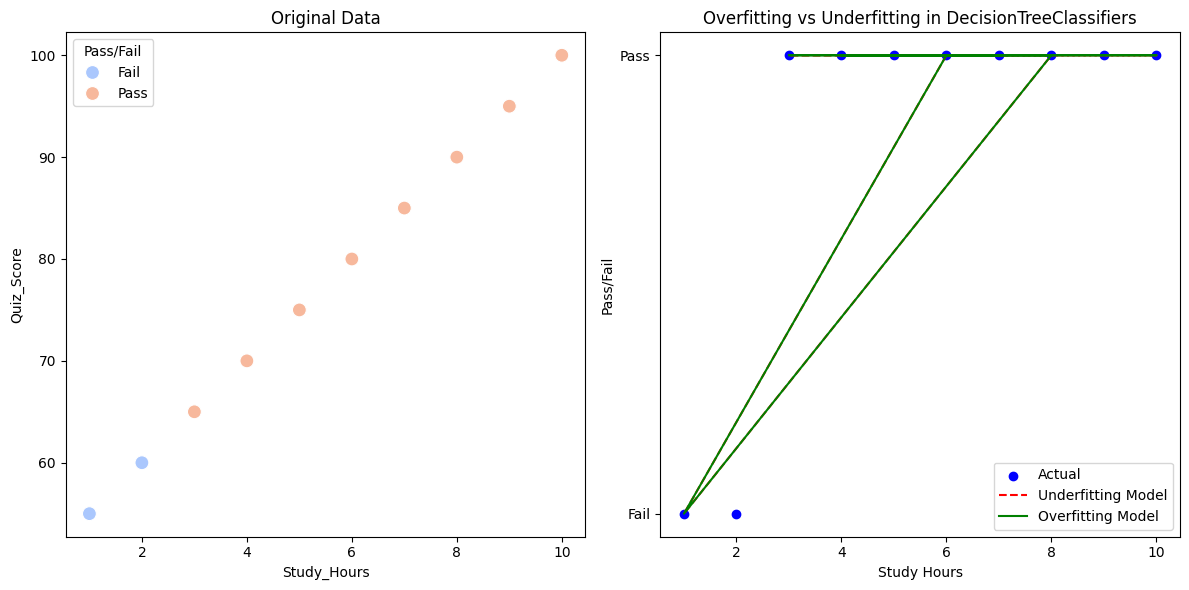

In [ ]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(data=data, x='Study_Hours', y='Quiz_Score', hue='Pass/Fail', palette='coolwarm', s=100)
plt.title('Original Data')

plt.subplot(1, 2, 2)
plt.scatter(X['Study_Hours'], y.map({0:'Fail', 1:'Pass'}), color ='blue', label='Actual')

plt.plot(X_train['Study_Hours'], underfit_tree.predict(X_train), color='red', label='Underfitting Model', linestyle='--')

plt.plot(X_train['Study_Hours'], overfit_tree.predict(X_train), color='green', label='Overfitting Model', linestyle='-')
plt.xlabel('Study Hours')
plt.ylabel('Pass/Fail')
plt.legend()
plt.title('Overfitting vs Underfitting in DecisionTreeClassifiers')

plt.tight_layout()
plt.show()